# B2 – Rétropropagation et gradient checking
Ce notebook contient (1) les dérivations demandées pour le rapport, (2) le test du backward de `src/`, (3) le gradient checking par différences finies, (4) le test de sur-apprentissage sur un très petit jeu de données. Il valide le jalon **J1**.

## 1. Dérivations (pour le rapport)

**1) Propagation avant** (une observation $x$, $a^{(0)}=x$) :
$$z^{(1)}=W^{(1)}x+b^{(1)},\quad a^{(1)}=\mathrm{ReLU}(z^{(1)}),$$
$$z^{(2)}=W^{(2)}a^{(1)}+b^{(2)},\quad a^{(2)}=\mathrm{ReLU}(z^{(2)}),$$
$$z^{(3)}=W^{(3)}a^{(2)}+b^{(3)},\quad \hat y=\sigma(z^{(3)}).$$

**2) Dérivées des activations**
$$\mathrm{ReLU}'(z)=\mathbb 1[z>0],\qquad \sigma'(z)=\sigma(z)\bigl(1-\sigma(z)\bigr).$$

**3) Gradient de la loss par rapport à la sortie.** Pour $\ell(\hat y,y)=-y\log\hat y-(1-y)\log(1-\hat y)$ :
$$\frac{\partial \ell}{\partial \hat y}=-\frac{y}{\hat y}+\frac{1-y}{1-\hat y}=\frac{\hat y-y}{\hat y(1-\hat y)}.$$
Pour la perte moyenne $F_B=\frac1{|B|}\sum_{i\in B}\ell(\hat y_i,y_i)$, chaque exemple reçoit un facteur $1/|B|$.

**4) Relations récursives.** On note $\delta^{(\ell)}=\partial \ell/\partial z^{(\ell)}$. À la sortie, comme $\hat y=\sigma(z^{(3)})$ :
$$\delta^{(3)}=\frac{\partial \ell}{\partial \hat y}\,\sigma'(z^{(3)})=\frac{\hat y-y}{\hat y(1-\hat y)}\cdot\hat y(1-\hat y)=\hat y-y.$$
Pour les couches cachées (règle de la chaîne) :
$$\delta^{(\ell)}=\bigl(W^{(\ell+1)\top}\delta^{(\ell+1)}\bigr)\odot\mathbb 1[z^{(\ell)}>0],\qquad \ell=2,1.$$

**5) Gradients des poids et biais** :
$$\frac{\partial \ell}{\partial W^{(\ell)}}=\delta^{(\ell)}\,a^{(\ell-1)\top},\qquad \frac{\partial \ell}{\partial b^{(\ell)}}=\delta^{(\ell)}.$$
Sur un mini-batch, on moyenne : $\dfrac{\partial F_B}{\partial W^{(\ell)}}=\dfrac1{|B|}\sum_{i\in B}\delta_i^{(\ell)}a_i^{(\ell-1)\top}$, soit en matrices $\frac1{|B|}\Delta^{(\ell)\top}A^{(\ell-1)}$ et $\frac1{|B|}\Delta^{(\ell)\top}\mathbf 1$ pour $b$.

*Correspondance avec le code* : chaque couche a un `forward` qui stocke son entrée dans `cache`, et un `backward(grad_out)` qui renvoie le gradient par rapport à son entrée. `MLP.backward` part de `bce_grad` et parcourt les couches en sens inverse.

In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.data import load_data
from src.model import MLP
from src.losses import bce
from src.gradcheck import gradient_check, numerical_gradient, relative_error

SEED = 42
data = load_data(seed=SEED)
X_train, y_train = data["X_train"], data["y_train"]

## 2. Dimensions des gradients

In [2]:
model = MLP(seed=SEED)
loss = model.loss_and_grad(X_train[:50], y_train[:50])
print("loss :", loss)
for i, l in enumerate(model.linear_layers(), 1):
    print(f"couche {i} : W {l.W.shape} / dW {l.dW.shape} | b {l.b.shape} / db {l.db.shape}")
    assert l.dW.shape == l.W.shape and l.db.shape == l.b.shape
assert np.all(np.isfinite(model.get_grads()))

loss : 0.675697059264132
couche 1 : W (16, 2) / dW (16, 2) | b (16,) / db (16,)
couche 2 : W (8, 16) / dW (8, 16) | b (8,) / db (8,)
couche 3 : W (1, 8) / dW (1, 8) | b (1,) / db (1,)


## 3. Gradient checking (différences centrées, $\varepsilon=10^{-5}$)
$$\frac{\partial F}{\partial \theta_j}\approx\frac{F(\theta+\varepsilon e_j)-F(\theta-\varepsilon e_j)}{2\varepsilon},\qquad \mathrm{err}=\frac{\|g_{ana}-g_{num}\|}{\|g_{ana}\|+\|g_{num}\|+\varepsilon}.$$
Règle usuelle : err $<10^{-7}$ excellent, $<10^{-5}$ acceptable, $>10^{-3}$ probablement un bug.

In [3]:
Xs, ys = X_train[:50], y_train[:50]
err, g_a, g_n = gradient_check(model, Xs, ys, eps=1e-5)
print(f"Erreur relative globale : {err:.2e}")
assert err < 1e-6

Erreur relative globale : 4.74e-11


Détail par couche (W et b séparément) pour localiser un éventuel bug :

In [4]:
rows, i = [], 0
for k, l in enumerate(model.linear_layers(), 1):
    for name, size in [(f"W{k}", l.W.size), (f"b{k}", l.b.size)]:
        e = relative_error(g_a[i:i+size], g_n[i:i+size])
        rows.append((name, size, e)); i += size

print(f"{'bloc':5s} {'taille':>7s} {'erreur relative':>16s}")
for name, size, e in rows:
    print(f"{name:5s} {size:7d} {e:16.2e}")
assert max(e for _, _, e in rows) < 1e-6

bloc   taille  erreur relative
W1         32         6.66e-11
b1         16         6.80e-11
W2        128         4.70e-11
b2          8         4.43e-11
W3          8         1.74e-11
b3          1         2.86e-11


Robustesse : plusieurs initialisations et tailles de batch différentes.

In [5]:
errs = []
for seed in range(5):
    for n in (1, 10, 100):
        m = MLP(seed=seed)
        e, _, _ = gradient_check(m, X_train[:n], y_train[:n])
        errs.append(e)
print(f"erreur max sur {len(errs)} configurations : {max(errs):.2e}")
assert max(errs) < 1e-6

erreur max sur 15 configurations : 9.47e-11


**Test de sensibilité** : le gradient checking doit détecter un gradient faux. On casse volontairement le backward (on oublie de diviser par $|B|$) pour vérifier que l'erreur explose.

In [6]:
m = MLP(seed=SEED)
m.loss_and_grad(Xs, ys)
g_bug = m.get_grads() * len(Xs)           # gradient volontairement faux
g_num = numerical_gradient(m, Xs, ys)
print(f"erreur avec gradient faux : {relative_error(g_bug, g_num):.2e}  (doit être grande)")
assert relative_error(g_bug, g_num) > 1e-2

erreur avec gradient faux : 9.61e-01  (doit être grande)


## 4. Sur-apprentissage d'un très petit jeu de données
Avec 20 points, le réseau (193 paramètres) doit pouvoir atteindre une loss proche de 0 et 100 % d'accuracy. Ici on utilise une simple descente de gradient écrite à la main ; les vrais optimiseurs viennent en partie C.

loss initiale : 0.8002 -> finale : 0.00060
accuracy sur les 20 points : 1.00


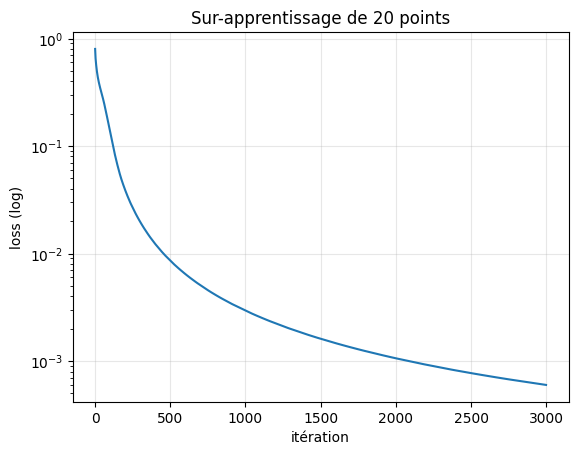

In [7]:
X_small, y_small = X_train[:20], y_train[:20]
m = MLP(seed=1)
losses = []
for k in range(3000):
    losses.append(m.loss_and_grad(X_small, y_small))
    m.set_params(m.get_params() - 0.1 * m.get_grads())

print(f"loss initiale : {losses[0]:.4f} -> finale : {losses[-1]:.5f}")
print(f"accuracy sur les 20 points : {m.accuracy(X_small, y_small):.2f}")
assert losses[-1] < 0.01 and m.accuracy(X_small, y_small) == 1.0

plt.semilogy(losses); plt.xlabel("itération"); plt.ylabel("loss (log)")
plt.title("Sur-apprentissage de 20 points"); plt.grid(alpha=.3); plt.show()

## Bilan J1
- Forward : dimensions cohérentes, loss finie (notebook 02)
- Gradient checking : erreur relative très faible, quelle que soit la graine ou la taille de batch
- Le test de sensibilité confirme que le contrôle détecte un gradient faux
- La loss diminue jusqu'à ~0 sur un très petit jeu de données

Le **jalon J1 est validé**. On peut passer aux optimiseurs (partie C).